### **Problem Statement**
A retail chain with 60 stores across 20 Kenyan counties has transaction data but no unified view of what drives its sales. It doesn’t know which stores, categories and customers generate the most revenue, whether its promotions create real incremental sales or just discount purchases that would have happened anyway, or how to plan demand.

#### **Objectives**
- Which counties, store formats, and product categories are our primary drivers of revenue and sales volume?
- What are the long-term sales trends over time, and how do sales fluctuate by the day of the week?
- What is the exact lift in units and revenue generated by our promotions?
- How does promotional performance vary across different discount depths and product categories?
- Which specific promotions are failing to generate a positive return and are not worth running in the future?
- How can we cluster our 2,280 customers into distinct segments using RFM (Recency, Frequency, Monetary value) metrics?
- What are the defining profiles of each customer segment, and what targeted actions (such as specific retention strategies for drifting, high-value customers) should we implement for them?
- What are the projected weekly sales when forecasted by product category or store location?
- Does our forecasting model successfully outperform a naive baseline (e.g., achieving a lower MAPE than a "same as last week" approach)?

## 1. Setup and loading data
##### Loading the four datasets and checking their shape (rows and columns)

In [186]:
import pandas as pd
from pathlib import Path
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import HistGradientBoostingRegressor

In [127]:
DATA = Path("..") /"Data"/ "kenya_retail"

tx = pd.read_csv(DATA / "transactions.csv", parse_dates=["date"])
stores = pd.read_csv(DATA / "stores.csv")
customers = pd.read_csv(DATA / "customers.csv", parse_dates=["signup_date"])
products = pd.read_csv(DATA / "products.csv")

for name, df in [("transactions", tx), ("stores", stores),
                 ("customers", customers), ("products", products)]:
    print(name, df.shape)

transactions (1802309, 16)
stores (60, 6)
customers (2280, 7)
products (62849, 5)


### 2. Data audit 
##### Data types in each column of the table

In [128]:
for name, d in [("transactions", tx), ("stores", stores),
                ("customers", customers), ("products", products)]:
    print(f"\n=== {name} {d.shape} ===")
    print(d.dtypes.to_string())


=== transactions (1802309, 16) ===
line_id                     int64
basket_id                   int64
date               datetime64[ns]
hour                        int64
store_id                   object
customer_id                object
product_id                  int64
quantity                    int64
unit_price_kes            float64
gross_sales_kes           float64
discount_kes              float64
net_sales_kes             float64
promo_flag                  int64
promo_type                 object
payment_method             object
payment_ref                object

=== stores (60, 6) ===
store_id       object
county         object
tier           object
format         object
size_sqm        int64
opened_year     int64

=== customers (2280, 7) ===
customer_id               object
county                    object
signup_date       datetime64[ns]
loyalty_tier              object
age_band                  object
household_size            object
kids                      object

===

##### Checking the Missing values and duplicates in the raw transactions

In [129]:
print("Missing values in transactions:")
print(tx.isna().sum()[lambda s: s > 0])

print("\nFully duplicated rows:", tx.duplicated().sum())
print("Duplicate line_id:", tx["line_id"].duplicated().sum())

Missing values in transactions:
customer_id       142274
promo_type        894024
payment_method      5407
payment_ref       696552
dtype: int64

Fully duplicated rows: 3581
Duplicate line_id: 3597


##### Integrity checks: net = gross - discount, valid store/product/customer IDs, sensible ranges

In [130]:
# arithmetic: net should equal gross minus discount
print("net != gross - discount:",
      ((tx["gross_sales_kes"] - tx["discount_kes"] - tx["net_sales_kes"]).abs() > 1).sum())

# foreign keys: every store/product/customer should exist in its table
print("unknown stores:", (~tx["store_id"].isin(stores["store_id"])).sum())
print("unknown products:", (~tx["product_id"].isin(products["product_id"])).sum())
print("unknown customers:",
      (~tx["customer_id"].dropna().isin(customers["customer_id"])).sum())

net != gross - discount: 0
unknown stores: 0
unknown products: 0
unknown customers: 0


##### Sanity ranges
Checking for non-positive quantities and prices, then prints the date range and the hours seen.

In [131]:
print("\nnon-positive quantity:", (tx["quantity"] <= 0).sum())
print("non-positive price:", (tx["unit_price_kes"] <= 0).sum())
print("date range:", tx["date"].min().date(), "->", tx["date"].max().date())
print("hours seen:", sorted(tx["hour"].unique()))


non-positive quantity: 0
non-positive price: 0
date range: 2024-01-01 -> 2025-12-11
hours seen: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


##### Categorical values (payment method, promo type)

In [132]:
for c in ["payment_method", "promo_type"]:
    print(tx[c].value_counts(dropna=False), "\n")

payment_method
M-Pesa           1031581
Cash              425717
Card              242853
Airtel Money       70830
Bank Transfer      25921
NaN                 5407
Name: count, dtype: int64 

promo_type
NaN                 894024
Loyalty discount    461364
Shelf promo         439917
Coupon                7004
Name: count, dtype: int64 



## 3. Data cleaning
- Dropping duplicated rows
- Filling blank payment methods with **Unknown** 
- Keepping rows with a missing customer ID and flag them (`has_customer_id`) instead of dropping or filling them. These are anonymous shoppers: they count in sales and promo analysis but not in customer segmentation.

In [133]:
n0 = len(tx)

tx = tx.drop_duplicates(subset="line_id")                
tx["payment_method"] = tx["payment_method"].fillna("Unknown")
tx["has_customer_id"] = tx["customer_id"].notna()          

print(f"rows: {n0:,} -> {len(tx):,}  (removed {n0 - len(tx):,} duplicates)")

rows: 1,802,309 -> 1,798,712  (removed 3,597 duplicates)


## 4. Merging the tables
##### Merging stores, products and customers onto the transactions and previewing the first 5 rows

In [134]:
df = (tx
      .merge(stores.rename(columns={"county": "store_county"}), on="store_id", how="left")
      .merge(products, on="product_id", how="left")
      .merge(customers[["customer_id", "county", "loyalty_tier"]]
             .rename(columns={"county": "customer_county"}),
             on="customer_id", how="left"))
pd.set_option('display.max_columns', None)
df.head()

,line_id,basket_id,date,hour,store_id,customer_id,product_id,quantity,unit_price_kes,gross_sales_kes,discount_kes,net_sales_kes,promo_flag,promo_type,payment_method,payment_ref,has_customer_id,store_county,tier,format,size_sqm,opened_year,category,product_group,product_subgroup,brand,customer_county,loyalty_tier
0,1,26984851472,2024-01-01,16,KE-ST042,C02166,1004906,1,140.0,140.0,43.0,97.0,1,Shelf promo,M-Pesa,VJJ2SFXNQR,True,Bungoma,Rural,Mini-market,448,2013,PRODUCE,POTATOES,POTATOES RUSSET (BULK&BAG),Private,Bungoma,Silver
1,2,26984851472,2024-01-01,16,KE-ST042,C02166,1033142,1,60.0,60.0,-0.0,60.0,0,NaN,M-Pesa,VJJ2SFXNQR,True,Bungoma,Rural,Mini-market,448,2013,PRODUCE,ONIONS,ONIONS SWEET (BULK&BAG),National,Bungoma,Silver
2,3,26984851472,2024-01-01,16,KE-ST042,C02166,1036325,1,90.0,90.0,21.0,69.0,0,Loyalty discount,M-Pesa,VJJ2SFXNQR,True,Bungoma,Rural,Mini-market,448,2013,PRODUCE,VEGETABLES - ALL OTHERS,CELERY,Private,Bungoma,Silver
3,4,26984851472,2024-01-01,16,KE-ST042,C02166,1082185,1,85.0,85.0,-0.0,85.0,0,NaN,M-Pesa,VJJ2SFXNQR,True,Bungoma,Rural,Mini-market,448,2013,PRODUCE,TROPICAL FRUIT,BANANAS,National,Bungoma,Silver
4,5,26984851472,2024-01-01,16,KE-ST042,C02166,8160430,1,135.0,135.0,28.0,107.0,0,Loyalty discount,M-Pesa,VJJ2SFXNQR,True,Bungoma,Rural,Mini-market,448,2013,PRODUCE,ORGANICS FRUIT & VEGETABLES,ORGANIC CARROTS,Private,Bungoma,Silver


##### Checking the merged dataframe

In [135]:
df.columns

Index(['line_id', 'basket_id', 'date', 'hour', 'store_id', 'customer_id',
       'product_id', 'quantity', 'unit_price_kes', 'gross_sales_kes',
       'discount_kes', 'net_sales_kes', 'promo_flag', 'promo_type',
       'payment_method', 'payment_ref', 'has_customer_id', 'store_county',
       'tier', 'format', 'size_sqm', 'opened_year', 'category',
       'product_group', 'product_subgroup', 'brand', 'customer_county',
       'loyalty_tier'],
      dtype='object')

In [136]:
#pd.set_option('display.max_columns', None)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1798712 entries, 0 to 1798711
Data columns (total 28 columns):
 #   Column            Dtype         
---  ------            -----         
 0   line_id           int64         
 1   basket_id         int64         
 2   date              datetime64[ns]
 3   hour              int64         
 4   store_id          object        
 5   customer_id       object        
 6   product_id        int64         
 7   quantity          int64         
 8   unit_price_kes    float64       
 9   gross_sales_kes   float64       
 10  discount_kes      float64       
 11  net_sales_kes     float64       
 12  promo_flag        int64         
 13  promo_type        object        
 14  payment_method    object        
 15  payment_ref       object        
 16  has_customer_id   bool          
 17  store_county      object        
 18  tier              object        
 19  format            object        
 20  size_sqm          int64         
 21  opened_y

In [137]:
df.isnull().sum()

line_id                  0
basket_id                0
date                     0
hour                     0
store_id                 0
customer_id         142013
product_id               0
quantity                 0
unit_price_kes           0
gross_sales_kes          0
discount_kes             0
net_sales_kes            0
promo_flag               0
promo_type          892202
payment_method           0
payment_ref         695142
has_customer_id          0
store_county             0
tier                     0
format                   0
size_sqm                 0
opened_year              0
category                 0
product_group            0
product_subgroup         0
brand                    0
customer_county     142013
loyalty_tier        142013
dtype: int64

In [138]:
df.duplicated().sum()

0

## 5. Feature engineering
##### Adding week, month and weekday columns used in the analysis below

In [139]:
df["week"] = df["date"].dt.to_period("W").dt.start_time
df["month"] = df["date"].dt.to_period("M")
df["weekday"] = df["date"].dt.day_name()

## 6. Exploratory analysis: sales drivers and trends
##### Total sales and top counties, store formats and categories
##### What is the Total sales, the leading counties in the total net sales?

In [140]:
print("Total net sales (KES):", f"{df['net_sales_kes'].sum():,.0f}")

print("\nTop counties:")
print(df.groupby("store_county")["net_sales_kes"].sum().sort_values(ascending=False).head(10))

Total net sales (KES): 372,308,106

Top counties:
store_county
Nairobi        58857488.0
Bungoma        51605051.0
Kakamega       37378722.0
Machakos       34664933.0
Kiambu         28740040.0
Trans Nzoia    20089244.0
Laikipia       18918265.0
Uasin Gishu    17144811.0
Kisumu         16618879.0
Murang'a       16517704.0
Name: net_sales_kes, dtype: float64


#### What are the net sales by store format?

In [141]:
print("\nBy store format:")
print(df.groupby("format")["net_sales_kes"].sum().sort_values(ascending=False))



By store format:
format
Supermarket    156673435.0
Mini-market    149999510.0
Hypermarket     65635161.0
Name: net_sales_kes, dtype: float64


### What are the Top product categories by net sales?

In [142]:
print("\nTop categories:")
print(df.groupby("category")["net_sales_kes"].sum().sort_values(ascending=False).head(10))


Top categories:
category
GROCERY          207357803.0
DRUG GM           52321103.0
PRODUCE           28958158.0
MEAT              26970144.0
MEAT-PCKGD        20268730.0
DELI              13324779.0
PASTRY             5929304.0
NUTRITION          5369794.0
SEAFOOD-PCKGD      3263650.0
FLORAL             2099985.0
Name: net_sales_kes, dtype: float64


##### What is the monthly net sales trend across the different months?

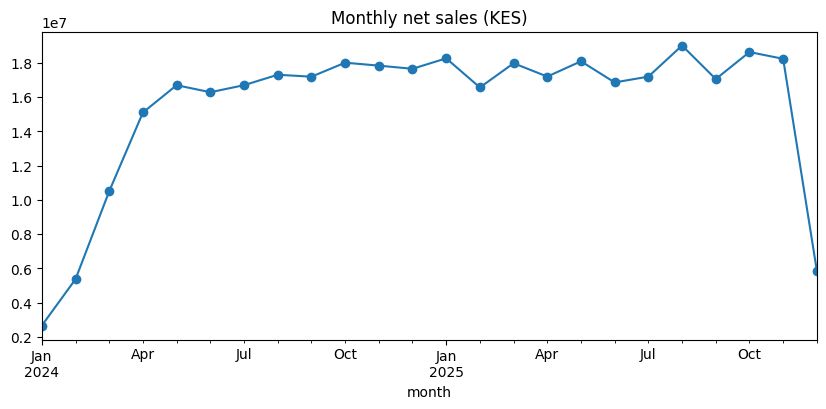

In [143]:
monthly = df.groupby("month")["net_sales_kes"].sum()
monthly.plot(figsize=(10, 4), title="Monthly net sales (KES)", marker="o");

## 7. Promotion analysis
##### What's the Overall promotion lift in units, and lift by category?

In [144]:
df["week"] = df["date"].dt.to_period("W").dt.start_time

# units sold per product, per store, per week, and whether a promo ran
pw = (df.groupby(["product_id", "store_id", "week"])
        .agg(units=("quantity", "sum"), promo=("promo_flag", "max"))
        .reset_index())

# average units in promo vs non-promo weeks, same product in the same store
avg = pw.groupby(["product_id", "store_id", "promo"])["units"].mean().unstack("promo")
cnt = pw.groupby(["product_id", "store_id", "promo"]).size().unstack("promo")

ok = (cnt[0] >= 3) & (cnt[1] >= 3)          # need enough weeks of each kind
lift = avg[ok].copy()
lift.columns = ["base_units", "promo_units"]
lift["lift"] = lift["promo_units"] / lift["base_units"]
lift = lift.reset_index().merge(
    products[["product_id", "category"]], on="product_id", how="left")

##### Summary of the promo lift
The number of product-store pairs analysed and the median lift.

In [145]:
print("product-store pairs analysed:", len(lift))
print("median lift:", lift["lift"].median().round(2))

product-store pairs analysed: 16456
median lift: 1.17


In [146]:
by_cat = (lift.groupby("category")["lift"]
              .agg(median="median", pairs="count")
              .query("pairs >= 30")
              .sort_values("median", ascending=False))
by_cat

,median,pairs
category,,
MEAT,1.333333,886
MEAT-PCKGD,1.289011,864
DRUG GM,1.280000,574
PRODUCE,1.235533,2110
PASTRY,1.200000,131
GROCERY,1.125000,11575
SALAD BAR,1.110171,36
DELI,1.095465,138
NUTRITION,1.060606,87


##### Unit lift and revenue lift by discount depth

In [147]:
pw = (df.groupby(["product_id", "store_id", "week"])
        .agg(units=("quantity", "sum"), revenue=("net_sales_kes", "sum"),
             gross=("gross_sales_kes", "sum"), disc=("discount_kes", "sum"),
             promo=("promo_flag", "max"))
        .reset_index())
pw["disc_pct"] = pw["disc"] / pw["gross"]

base = (pw[pw["promo"] == 0].groupby(["product_id", "store_id"])
          .agg(base_units=("units", "mean"), base_rev=("revenue", "mean"),
               base_weeks=("units", "size")))

promo = (pw[pw["promo"] == 1]
         .merge(base, left_on=["product_id", "store_id"], right_index=True))
promo = promo[promo["base_weeks"] >= 3].copy()

promo["unit_lift"] = promo["units"] / promo["base_units"]
promo["rev_lift"] = promo["revenue"] / promo["base_rev"]
promo["depth"] = pd.cut(promo["disc_pct"], bins=[0, 0.25, 0.35, 0.45, 0.61],
                        labels=["<25%", "25-35%", "35-45%", "45%+"])


##### Median lift by discount depth

In [148]:
(promo.groupby("depth", observed=True)
      .agg(median_unit_lift=("unit_lift", "median"),
           median_rev_lift=("rev_lift", "median"),
           promo_weeks=("unit_lift", "size")))

,median_unit_lift,median_rev_lift,promo_weeks
depth,,,
<25%,1.373134,1.140987,9793
25-35%,1.000000,0.755245,61798
35-45%,1.000000,0.682207,44098
45%+,1.000000,0.649380,33055


##### Robustness check: fast-moving products only (base units of 5 or more per week)

In [149]:
fast = promo[promo["base_units"] >= 5]

check = fast.groupby("depth", observed=True).agg(
    promo_units=("units", "sum"), base_units=("base_units", "sum"),
    promo_rev=("revenue", "sum"), base_rev=("base_rev", "sum"),
    promo_weeks=("units", "size"))

check["unit_lift"] = check["promo_units"] / check["base_units"]
check["rev_lift"] = check["promo_rev"] / check["base_rev"]
check[["unit_lift", "rev_lift", "promo_weeks"]]

,unit_lift,rev_lift,promo_weeks
depth,,,
<25%,1.287209,1.089678,150
25-35%,0.892431,0.711518,398
35-45%,1.023606,0.696826,338
45%+,0.936691,0.443533,279


##### Finding
Promotions of 25% and deeper reduce revenue per promoted product in the store: units sold barely rise, while the price cut lowers revenue.

## 8. Sales patterns by weekday, hour and store
##### How do average daily net sales vary by day of the week?

weekday
Monday       446869.0
Tuesday      443773.0
Wednesday    497347.0
Thursday     620443.0
Friday       689335.0
Saturday     507940.0
Sunday       467452.0
Name: net_sales_kes, dtype: float64

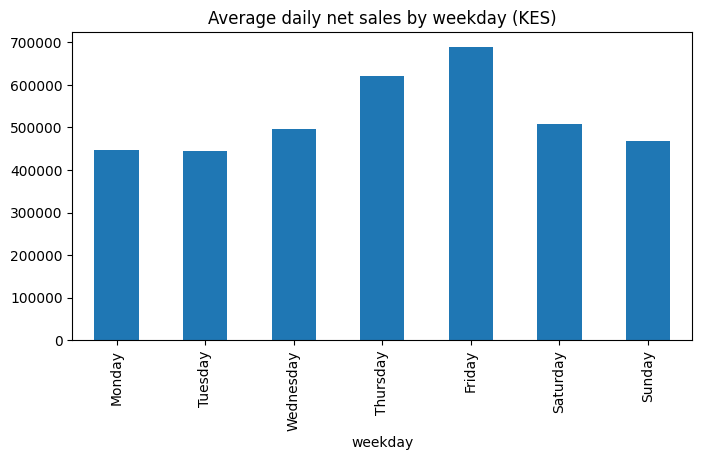

In [150]:
daily = df.groupby("date")["net_sales_kes"].sum().reset_index()
daily["weekday"] = daily["date"].dt.day_name()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = daily.groupby("weekday")["net_sales_kes"].mean().reindex(order)

by_day.plot.bar(figsize=(8, 4), title="Average daily net sales by weekday (KES)")
by_day.round(0)

##### How do net sales vary by hour of the day?

<Axes: title={'center': 'Net sales by hour of day'}, xlabel='hour'>

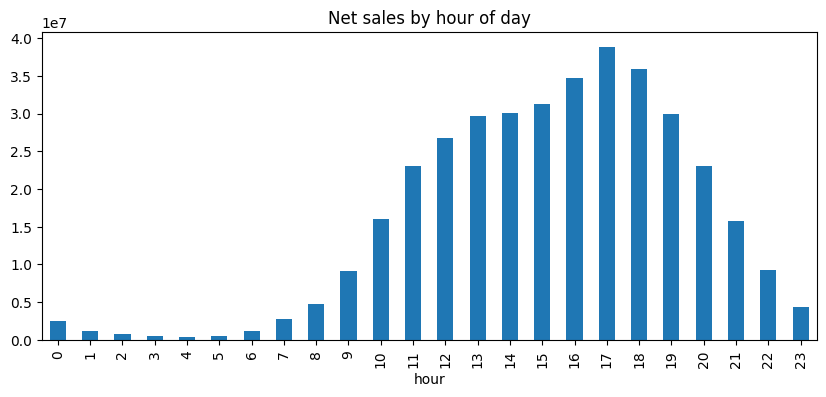

In [151]:
df.groupby("hour")["net_sales_kes"].sum().plot.bar(figsize=(10, 4), title="Net sales by hour of day")

##### How do sales per store and basket size compare across store formats?

In [152]:
def per_store(col):
    t = df.groupby(col).agg(sales=("net_sales_kes", "sum"),
                            stores=("store_id", "nunique"),
                            baskets=("basket_id", "nunique"))
    t["sales_per_store"] = (t["sales"] / t["stores"]).round(0)
    t["avg_basket_kes"] = (t["sales"] / t["baskets"]).round(0)
    return t.sort_values("sales_per_store", ascending=False)

per_store("format")

,sales,stores,baskets,sales_per_store,avg_basket_kes
format,,,,,
Hypermarket,65635161.0,6,28287,10939194.0,2320.0
Supermarket,156673435.0,24,73278,6528060.0,2138.0
Mini-market,149999510.0,30,68080,4999984.0,2203.0


##### Which counties lead on sales per store? (top 10)

In [153]:
per_store("store_county").head(10)

,sales,stores,baskets,sales_per_store,avg_basket_kes
store_county,,,,,
Kilifi,9624743.0,1,4240,9624743.0,2270.0
Kakamega,37378722.0,4,16272,9344680.0,2297.0
Uasin Gishu,17144811.0,2,7059,8572406.0,2429.0
Kirinyaga,6785666.0,1,3547,6785666.0,1913.0
Kisii,13527425.0,2,5600,6763712.0,2416.0
Trans Nzoia,20089244.0,3,11159,6696415.0,1800.0
Nyeri,6370318.0,1,2450,6370318.0,2600.0
Laikipia,18918265.0,3,8999,6306088.0,2102.0
Nairobi,58857488.0,10,28461,5885749.0,2068.0


## 9. Promotion analysis with whole-week promos
##### Tightening the promo definition and recomputing the lift
The earlier analysis marks a week as a promo week when any sale in it carries a promotion. This section is stricter: a promo week has at least 80% of its units sold on promotion, and the baseline uses only weeks with no promo units. Each product-store pair needs at least 3 baseline weeks and an average of 5 or more units per week.

In [154]:
df["promo_units"] = df["quantity"] * df["promo_flag"]

pw = (df.groupby(["product_id", "store_id", "week"])
        .agg(units=("quantity", "sum"), promo_units=("promo_units", "sum"),
             revenue=("net_sales_kes", "sum"),
             gross=("gross_sales_kes", "sum"), disc=("discount_kes", "sum"))
        .reset_index())
pw["promo_share"] = pw["promo_units"] / pw["units"]
pw["disc_pct"] = pw["disc"] / pw["gross"]


##### Baseline weeks and promo weeks
The baseline comes from weeks without promo units, and promo weeks are those with at least 80% of units on promotion.

In [155]:
base = (pw[pw["promo_share"] == 0].groupby(["product_id", "store_id"])
          .agg(base_units=("units", "mean"), base_rev=("revenue", "mean"),
               base_weeks=("units", "size")))

p = (pw[pw["promo_share"] >= 0.8]
     .merge(base, left_on=["product_id", "store_id"], right_index=True)
     .merge(products[["product_id", "category"]], on="product_id", how="left"))
p = p[(p["base_weeks"] >= 3) & (p["base_units"] >= 5)].copy()

##### Lift and discount depth per promo week

In [156]:
p["unit_lift"] = p["units"] / p["base_units"]
p["rev_lift"] = p["revenue"] / p["base_rev"]
p["depth"] = pd.cut(p["disc_pct"], bins=[0, 0.25, 0.35, 0.45, 0.61],
                    labels=["<25%", "25-35%", "35-45%", "45%+"])
print("promo weeks analysed:", len(p))

promo weeks analysed: 969


##### Unit lift and revenue lift by discount depth

In [157]:
out = p.groupby("depth", observed=True).agg(
    promo_units=("units", "sum"), base_units=("base_units", "sum"),
    promo_rev=("revenue", "sum"), base_rev=("base_rev", "sum"),
    weeks=("units", "size"))
out["unit_lift"] = out["promo_units"] / out["base_units"]
out["rev_lift"] = out["promo_rev"] / out["base_rev"]
out[["unit_lift", "rev_lift", "weeks"]]

,unit_lift,rev_lift,weeks
depth,,,
<25%,0.995567,0.751686,6
25-35%,0.851306,0.689198,353
35-45%,1.010935,0.691153,332
45%+,0.934305,0.441978,278


##### Unit lift and revenue lift by category
Only categories with at least 30 promo weeks appear.

In [158]:
cat = p.groupby("category").agg(
    promo_units=("units", "sum"), base_units=("base_units", "sum"),
    promo_rev=("revenue", "sum"), base_rev=("base_rev", "sum"),
    weeks=("units", "size")).query("weeks >= 30")
cat["unit_lift"] = cat["promo_units"] / cat["base_units"]
cat["rev_lift"] = cat["promo_rev"] / cat["base_rev"]
cat[["unit_lift", "rev_lift", "weeks"]].sort_values("rev_lift", ascending=False)

,unit_lift,rev_lift,weeks
category,,,
PRODUCE,1.164969,0.784519,315
GROCERY,0.876014,0.600113,564
DRUG GM,0.554522,0.557288,56


##### Which promotions fail to pay back?
A promo week fails when its revenue lift is below 1, meaning it earns less revenue than the baseline. The table shows the share of failing weeks by category.

In [159]:
p["failed"] = p["rev_lift"] < 1

print("overall share failing:", p["failed"].mean().round(3))
(p.groupby("category")["failed"].agg(share_failing="mean", weeks="size")
   .query("weeks >= 30").sort_values("share_failing", ascending=False))

overall share failing: 0.776


,share_failing,weeks
category,,
DRUG GM,0.928571,56
GROCERY,0.773050,564
PRODUCE,0.749206,315


## 10. Customer segmentation (RFM)
##### Computing recency, frequency and monetary value per customer
Only customers with an ID enter the segmentation. Recency is the number of days since the last purchase, measured from a snapshot date one day after the last transaction. Frequency is the number of unique baskets, and monetary is the total net spend.

In [160]:
known = df[df["has_customer_id"]]
snapshot = known["date"].max() + pd.Timedelta(days=1)

rfm = known.groupby("customer_id").agg(
    recency=("date", lambda s: (snapshot - s.max()).days),
    frequency=("basket_id", "nunique"),
    monetary=("net_sales_kes", "sum"))

##### Distribution of the RFM metrics

In [161]:
print(rfm.shape)
rfm.describe().round(1)

(2273, 3)


,recency,frequency,monetary
count,2273.0,2273.0,2273.0
mean,59.1,68.7,150903.6
std,112.3,84.6,179591.6
min,1.0,1.0,70.0
25%,4.0,17.0,28292.0
50%,14.0,44.0,87545.0
75%,55.0,91.0,205888.0
max,676.0,1026.0,1388044.0


##### Choosing the number of clusters
The RFM values are log-transformed and standardised before KMeans runs for 2 to 7 clusters. The silhouette score and the inertia guide the choice of K.

In [162]:
X = StandardScaler().fit_transform(np.log1p(rfm))

for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    print(k, "silhouette:", round(silhouette_score(X, km.labels_), 3), "inertia:", round(km.inertia_))

2 silhouette: 0.468 inertia: 3116
3 silhouette: 0.373 inertia: 2199
4 silhouette: 0.365 inertia: 1787
5 silhouette: 0.329 inertia: 1490
6 silhouette: 0.282 inertia: 1302
7 silhouette: 0.303 inertia: 1135


##### Fitting the final clustering model

In [163]:
K = 4   # change this after looking at the silhouette scores

km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_

##### Profiling each cluster
The table shows the median recency, frequency and spend of each cluster, together with its share of customers and of total spend.

In [164]:
profile = rfm.groupby("cluster").agg(
    customers=("monetary", "size"),
    recency_days=("recency", "median"),
    baskets=("frequency", "median"),
    spend_kes=("monetary", "median"),
    total_spend=("monetary", "sum"))
profile["share_of_customers"] = (profile["customers"] / profile["customers"].sum()).round(3)
profile["share_of_spend"] = (profile["total_spend"] / profile["total_spend"].sum()).round(3)
profile.sort_values("spend_kes", ascending=False).round(1)

,customers,recency_days,baskets,spend_kes,total_spend,share_of_customers,share_of_spend
cluster,,,,,,,
3,919,4.0,103.0,234815.0,265807952.0,0.4,0.8
0,535,53.0,37.0,80229.0,55006703.0,0.2,0.2
2,462,9.0,21.0,34449.0,18995461.0,0.2,0.1
1,357,181.0,5.0,6864.0,3193699.0,0.2,0.0


##### Loyalty tier and age band by cluster

In [165]:
info = customers.set_index("customer_id")[["loyalty_tier", "age_band", "county"]]
seg = rfm.join(info)

print(pd.crosstab(seg["cluster"], seg["loyalty_tier"], normalize="index").round(2))
print(pd.crosstab(seg["cluster"], seg["age_band"], normalize="index").round(2))

loyalty_tier  Bronze  Gold  Silver
cluster                           
0               0.55  0.04    0.41
1               1.00  0.00    0.00
2               0.93  0.00    0.07
3               0.06  0.35    0.59
age_band  19-24  25-34  35-44  45-54  55-64   65+
cluster                                          
0          0.04   0.20   0.23   0.37   0.06  0.09
1          0.02   0.23   0.23   0.26   0.14  0.12
2          0.07   0.10   0.20   0.40   0.12  0.12
3          0.06   0.19   0.25   0.36   0.07  0.08


##### Category mix by cluster
The table shows the share of each cluster's spend across the six largest categories.

In [166]:
mix = (known.merge(rfm[["cluster"]], left_on="customer_id", right_index=True)
            .pivot_table(index="cluster", columns="category", values="net_sales_kes",
                         aggfunc="sum", fill_value=0))
mix = mix.div(mix.sum(axis=1), axis=0)
mix[mix.sum().nlargest(6).index].round(2)

category,GROCERY,DRUG GM,PRODUCE,MEAT,MEAT-PCKGD,DELI
cluster,,,,,,
0,0.55,0.13,0.07,0.08,0.07,0.03
1,0.53,0.14,0.08,0.07,0.06,0.04
2,0.56,0.13,0.08,0.07,0.06,0.03
3,0.56,0.14,0.08,0.07,0.05,0.04


#### Visualizing the clusters

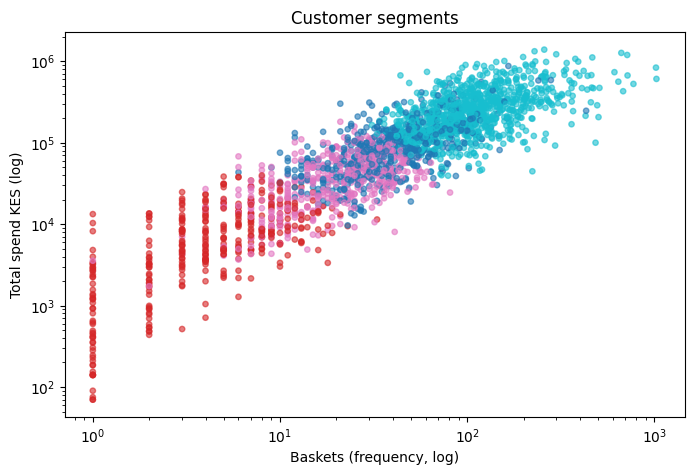

In [167]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rfm["frequency"], rfm["monetary"], c=rfm["cluster"], cmap="tab10", alpha=0.6, s=15)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Baskets (frequency, log)"); ax.set_ylabel("Total spend KES (log)")
ax.set_title("Customer segments"); plt.show()

##### Naming the segments
Each cluster number maps to a segment name. The names are placeholders and need to match the cluster profiles above.

In [ ]:
names = {0: "Champions", 1: "Loyal regulars", 2: "At-risk", 3: "Lapsed"}
rfm["segment"] = rfm["cluster"].map(names)
rfm["segment"].value_counts()

segment
Lapsed            919
Champions         535
At-risk           462
Loyal regulars    357
Name: count, dtype: int64

## 11. Weekly sales forecasting
##### Preparing weekly sales by category
Only complete weeks (seven days of data) and the eight largest categories enter the forecast.

In [169]:
days_per_week = df.groupby("week")["date"].nunique()
good_weeks = days_per_week[days_per_week == 7].index

top_cats = df.groupby("category")["net_sales_kes"].sum().nlargest(8).index


#### What is the weekly net sales by category?

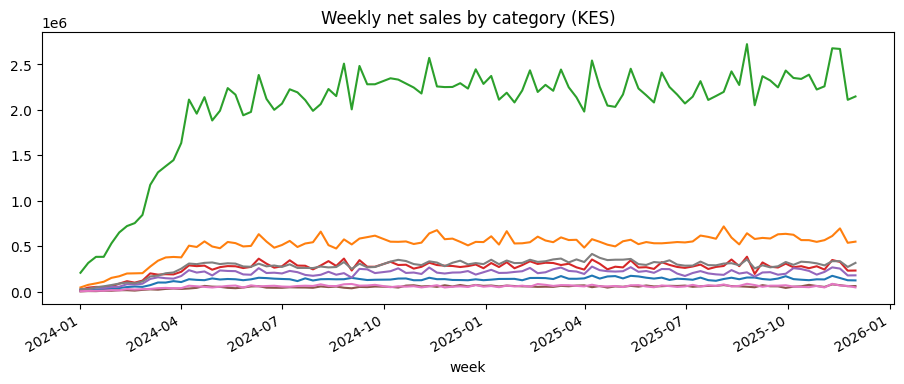

In [170]:
wk = (df[df["week"].isin(good_weeks) & df["category"].isin(top_cats)]
        .groupby(["week", "category"])["net_sales_kes"].sum()
        .unstack("category").reindex(good_weeks).fillna(0).sort_index())
wk.plot(figsize=(11, 4), title="Weekly net sales by category (KES)", legend=False);

##### Building the lag features
For each category, the code creates lags of 1 to 4 weeks, a rolling average of the previous 4 weeks and the week of the year.

In [171]:
rows = []
for cat in wk.columns:
    s = wk[cat]
    d = pd.DataFrame({"week": s.index, "category": cat, "sales": s.values})
    for l in (1, 2, 3, 4):
        d[f"lag{l}"] = s.shift(l).values
    d["roll4"] = s.shift(1).rolling(4).mean().values
    d["woy"] = d["week"].dt.isocalendar().week.astype(int).values
    rows.append(d)

data = pd.concat(rows).dropna().reset_index(drop=True)
data["cat_code"] = data["category"].astype("category").cat.codes
print(data.shape)

(768, 10)


##### Splitting into train and test sets
The last 12 weeks form the test set, and all earlier weeks train the model.

In [172]:
TEST_WEEKS = 12
cutoff = sorted(data["week"].unique())[-TEST_WEEKS]
train = data[data["week"] < cutoff]
test = data[data["week"] >= cutoff].copy()

features = ["lag1", "lag2", "lag3", "lag4", "roll4", "woy", "cat_code"]
print("train weeks:", train["week"].nunique(), "| test weeks:", test["week"].nunique())

train weeks: 84 | test weeks: 12


##### Training the model and setting the baselines
A gradient boosting model trains on the lag features. Two baselines serve as the comparison: the same as last week and the average of the last 4 weeks.

In [ ]:
model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)
model.fit(train[features], train["sales"])

test["model"] = model.predict(test[features])
test["naive"] = test["lag1"]          # same as last week
test["avg4"] = test["roll4"]          # average of the last 4 weeks

##### Evaluating the forecasts with MAPE
The overall MAPE compares the model with both baselines.

In [174]:
def mape(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat)
    m = y > 0
    return np.mean(np.abs(y[m] - yhat[m]) / y[m]) * 100

overall = {c: round(mape(test["sales"], test[c]), 1) for c in ["naive", "avg4", "model"]}
print("Overall MAPE %:", overall)

Overall MAPE %: {'naive': 12.2, 'avg4': 11.2, 'model': 11.2}


##### MAPE by category
The table flags the categories where the model beats the "same as last week" baseline.

In [175]:
by_cat = (test.groupby("category")
              .apply(lambda g: pd.Series({c: mape(g["sales"], g[c]) for c in ["naive", "avg4", "model"]}))
              .round(1))
by_cat["model_beats_naive"] = by_cat["model"] < by_cat["naive"]
by_cat

,naive,avg4,model,model_beats_naive
category,,,,
DELI,10.7,10.9,8.1,True
DRUG GM,6.6,7.5,9.2,False
GROCERY,6.0,6.7,6.3,False
MEAT,13.6,12.8,15.4,False
MEAT-PCKGD,13.3,14.3,12.4,True
NUTRITION,18.3,13.0,12.8,True
PASTRY,19.4,16.5,19.4,False
PRODUCE,9.4,7.8,6.3,True


##### Forecast vs actual for the largest category

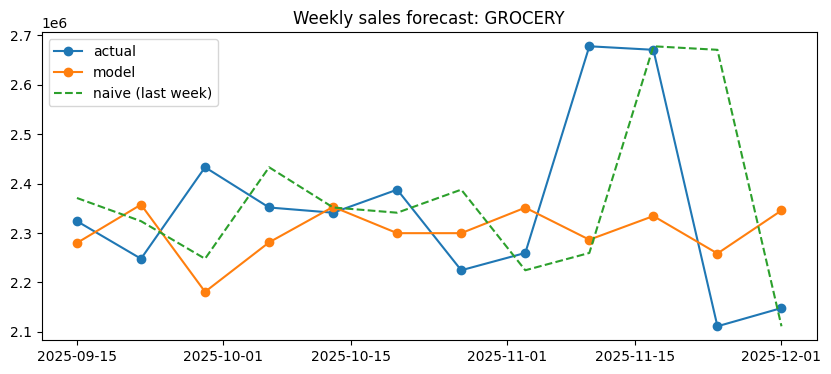

In [176]:
cat = top_cats[0]
g = test[test["category"] == cat].sort_values("week")
plt.figure(figsize=(10, 4))
plt.plot(g["week"], g["sales"], label="actual", marker="o")
plt.plot(g["week"], g["model"], label="model", marker="o")
plt.plot(g["week"], g["naive"], label="naive (last week)", linestyle="--")
plt.title(f"Weekly sales forecast: {cat}"); plt.legend(); plt.show() 

##### Reviewing the weekly totals
The plot shows weekly net sales across all top categories, and the table lists the weekly values from late October to early December 2025.

category,DELI,DRUG GM,GROCERY,MEAT,MEAT-PCKGD,NUTRITION,PASTRY,PRODUCE
week,,,,,,,,
2025-10-27,137350.0,549085.0,2224654.0,280797.0,188754.0,63304.0,64528.0,312775.0
2025-11-03,135838.0,567868.0,2259715.0,244401.0,218323.0,53713.0,47726.0,290169.0
2025-11-10,175565.0,613514.0,2678032.0,349492.0,268558.0,81376.0,87513.0,336698.0
2025-11-17,151495.0,697235.0,2670892.0,328975.0,255208.0,72747.0,68903.0,336230.0
2025-11-24,126728.0,538920.0,2111277.0,232323.0,179817.0,61254.0,64220.0,273193.0
2025-12-01,125089.0,551503.0,2148179.0,233743.0,180807.0,63322.0,48400.0,317926.0


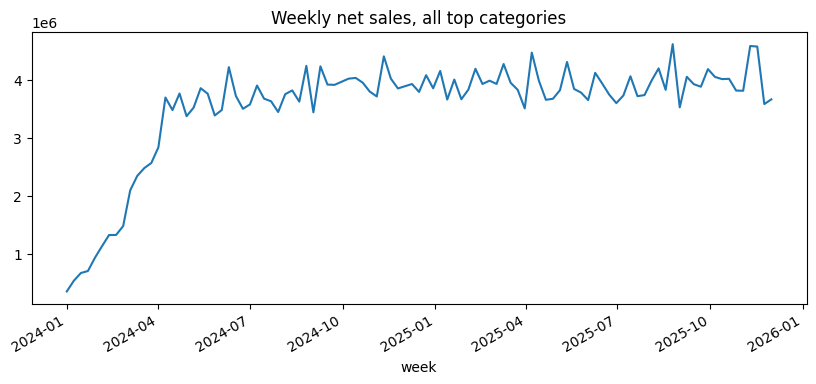

In [177]:
wk.sum(axis=1).plot(figsize=(10, 4), title="Weekly net sales, all top categories");
wk.loc["2025-10-27":"2025-12-01"].round(0)

In [178]:
wk.loc["2025-10-27":"2025-12-01"].round(0)

category,DELI,DRUG GM,GROCERY,MEAT,MEAT-PCKGD,NUTRITION,PASTRY,PRODUCE
week,,,,,,,,
2025-10-27,137350.0,549085.0,2224654.0,280797.0,188754.0,63304.0,64528.0,312775.0
2025-11-03,135838.0,567868.0,2259715.0,244401.0,218323.0,53713.0,47726.0,290169.0
2025-11-10,175565.0,613514.0,2678032.0,349492.0,268558.0,81376.0,87513.0,336698.0
2025-11-17,151495.0,697235.0,2670892.0,328975.0,255208.0,72747.0,68903.0,336230.0
2025-11-24,126728.0,538920.0,2111277.0,232323.0,179817.0,61254.0,64220.0,273193.0
2025-12-01,125089.0,551503.0,2148179.0,233743.0,180807.0,63322.0,48400.0,317926.0


##### Rebuilding the forecast with a seasonal baseline
The pipeline reruns on full weeks from 15 April 2024 onward and adds a third baseline, the same week last year (`lag52`). The last 12 weeks again form the test set.

In [179]:
START = pd.Timestamp("2024-04-15")
weeks = good_weeks[good_weeks >= START]

wk = (df[df["week"].isin(weeks) & df["category"].isin(top_cats)]
        .groupby(["week", "category"])["net_sales_kes"].sum()
        .unstack("category").reindex(weeks).fillna(0).sort_index())

#### Building the feature table

In [180]:
rows = []
for cat in wk.columns:
    s = wk[cat]
    d = pd.DataFrame({"week": s.index, "category": cat, "sales": s.values})
    for l in (1, 2, 3, 4):
        d[f"lag{l}"] = s.shift(l).values
    d["roll4"] = s.shift(1).rolling(4).mean().values
    d["lag52"] = s.shift(52).values            # same week last year (baseline only)
    d["woy"] = d["week"].dt.isocalendar().week.astype(int).values
    rows.append(d)

data = (pd.concat(rows)
          .dropna(subset=["lag1", "lag2", "lag3", "lag4", "roll4"])
          .reset_index(drop=True))
data["cat_code"] = data["category"].astype("category").cat.codes

#### Splitting into train and test sets

In [181]:
cutoff = sorted(data["week"].unique())[-12]
train = data[data["week"] < cutoff]
test = data[data["week"] >= cutoff].copy()
print("train weeks:", train["week"].nunique(), "| test weeks:", test["week"].nunique())

train weeks: 69 | test weeks: 12


##### Training the model and setting the baselines

In [182]:
features = ["lag1", "lag2", "lag3", "lag4", "roll4", "woy", "cat_code"]
model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)
model.fit(train[features], train["sales"])

test["model"] = model.predict(test[features])
test["naive"] = test["lag1"]
test["avg4"] = test["roll4"]
test["seasonal_naive"] = test["lag52"]

##### Overall MAPE
The code compares the model with all three baselines.

In [183]:
def mape2(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    m = (y > 0) & ~np.isnan(yhat)
    return np.mean(np.abs(y[m] - yhat[m]) / y[m]) * 100

cols = ["naive", "avg4", "seasonal_naive", "model"]
print("Overall MAPE %:", {c: round(mape2(test["sales"], test[c]), 1) for c in cols})

Overall MAPE %: {'naive': 12.2, 'avg4': 11.2, 'seasonal_naive': 9.7, 'model': 11.6}


#### Forecast vs actual with baselines

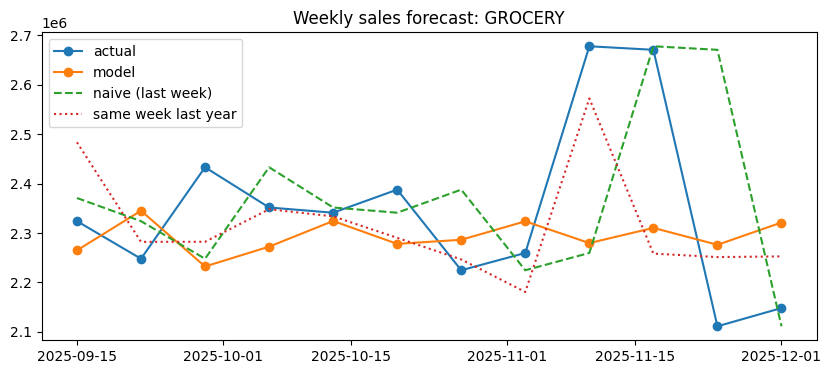

In [184]:
cat = top_cats[0]
g = test[test["category"] == cat].sort_values("week")
plt.figure(figsize=(10, 4))
plt.plot(g["week"], g["sales"], label="actual", marker="o")
plt.plot(g["week"], g["model"], label="model", marker="o")
plt.plot(g["week"], g["naive"], label="naive (last week)", linestyle="--")
plt.plot(g["week"], g["seasonal_naive"], label="same week last year", linestyle=":")
plt.title(f"Weekly sales forecast: {cat}"); plt.legend(); plt.show()

##### MAPE by category
The table compares every approach by category and flags the categories where the model beats the "same as last week" baseline.

In [185]:
print("Overall MAPE %:", {c: round(mape2(test["sales"], test[c]), 1) for c in cols})

by_cat = (test.groupby("category")
              .apply(lambda g: pd.Series({c: mape2(g["sales"], g[c]) for c in cols}))
              .round(1))
by_cat["model_beats_naive"] = by_cat["model"] < by_cat["naive"]
by_cat

Overall MAPE %: {'naive': 12.2, 'avg4': 11.2, 'seasonal_naive': 9.7, 'model': 11.6}


,naive,avg4,seasonal_naive,model,model_beats_naive
category,,,,,
DELI,10.7,10.9,9.7,8.9,True
DRUG GM,6.6,7.5,4.7,13.0,False
GROCERY,6.0,6.7,4.5,6.1,False
MEAT,13.6,12.8,14.0,16.0,False
MEAT-PCKGD,13.3,14.3,12.3,12.0,True
NUTRITION,18.3,13.0,16.1,14.2,True
PASTRY,19.4,16.5,10.6,15.2,True
PRODUCE,9.4,7.8,5.8,7.3,True


A gradient-boosting model with lag features beat the “same as last week” baseline in 5 of 8 categories, but only marginally on average (about 11.6% vs 12.2% MAPE). A seasonal baseline using the same week last year performed best overall (about 9.7%), showing that recurring seasonal patterns matter more than short-term momentum in this data.

In [187]:
prof = rfm.groupby("cluster").agg(
    customers=("monetary", "size"),
    recency=("recency", "median"),
    baskets=("frequency", "median"),
    spend=("monetary", "median"),
    total=("monetary", "sum"))
prof["pct_customers"] = 100 * prof["customers"] / prof["customers"].sum()
prof["pct_spend"] = 100 * prof["total"] / prof["total"].sum()

# name each cluster by comparing it with the overall medians (lower recency = more recent)
r_med, f_med, m_med = rfm["recency"].median(), rfm["frequency"].median(), rfm["monetary"].median()

def label(r):
    recent, frequent, big = r.recency <= r_med, r.baskets >= f_med, r.spend >= m_med
    if recent and frequent and big: return "Champions"
    if not recent and big:          return "At-risk high value"
    if recent and frequent:         return "Loyal regulars"
    if not recent and not frequent: return "Lapsed"
    return "Occasional shoppers"

prof["segment"] = prof.apply(label, axis=1)
# if two clusters get the same name, keep them apart
prof["segment"] = [f"{s} (cluster {i})" if d else s
                   for s, i, d in zip(prof["segment"], prof.index,
                                      prof["segment"].duplicated(keep=False))]

actions = {
    "Champions": "Reward and protect: loyalty perks, early access to offers",
    "Loyal regulars": "Grow basket size with cross-sell and bundles",
    "At-risk high value": "Win back before they lapse with a targeted offer",
    "Lapsed": "Low-cost reactivation, or deprioritise",
    "Occasional shoppers": "Encourage repeat visits with light incentives",
}
def action_for(seg):
    return next(v for k, v in actions.items() if seg.startswith(k))

print("| Segment | Customers | % of customers | % of spend | Median recency (days) | Median baskets | Median spend (KES) | Recommended action |")
print("|---|---|---|---|---|---|---|---|")
for _, r in prof.sort_values("spend", ascending=False).iterrows():
    print(f"| {r.segment} | {int(r.customers):,} | {r.pct_customers:.0f}% | {r.pct_spend:.0f}% | "
          f"{r.recency:.0f} | {r.baskets:.0f} | {r.spend:,.0f} | {action_for(r.segment)} |")

| Segment | Customers | % of customers | % of spend | Median recency (days) | Median baskets | Median spend (KES) | Recommended action |
|---|---|---|---|---|---|---|---|
| Champions | 919 | 40% | 77% | 4 | 103 | 234,815 | Reward and protect: loyalty perks, early access to offers |
| Lapsed (cluster 0) | 535 | 24% | 16% | 53 | 37 | 80,229 | Low-cost reactivation, or deprioritise |
| Occasional shoppers | 462 | 20% | 6% | 9 | 21 | 34,449 | Encourage repeat visits with light incentives |
| Lapsed (cluster 1) | 357 | 16% | 1% | 181 | 5 | 6,864 | Low-cost reactivation, or deprioritise |


In [188]:
prof["segment"] = prof["segment"].replace({
    "Lapsed (cluster 0)": "At-risk regulars",
    "Lapsed (cluster 1)": "Lapsed",
})
rfm["segment"] = rfm["cluster"].map(prof["segment"])
rfm["segment"].value_counts()

segment
Champions              919
At-risk regulars       535
Occasional shoppers    462
Lapsed                 357
Name: count, dtype: int64